# Fixed Income Risk Dashboard
### Task 01 · Daily Rates Desk Risk Report

**RiskHub Python Lab · Portfolio Valuation · Key-Rate DV01 · Historical Simulation VaR**

> **Business question:** What did the desk hold at the close, how much is it worth, and how vulnerable is the portfolio to the next day's interest-rate movements?

| As of | Live bond positions | Portfolio net value | Net Key-Rate DV01 | 1-day 99% HS VaR |
|:--|--:|--:|--:|--:|
| **2024-12-31** | **17** | **+&#36;324.34M** | **+&#36;47.23K / bp** | **&#36;939.31K** |

This notebook implements an **end-of-day, simulated fixed-income risk report**. It reconstructs a bond book from an amended trade blotter, discounts future cash flows using a zero-coupon yield curve, builds an eleven-vertex DV01 ladder, and applies 500 historical yield-curve shocks to estimate VaR.

**Stack:** Python · NumPy · pandas · Matplotlib · C#/.NET 10 · ClosedXML · Excel

**Provenance:** Educational exercise based on [RiskHub's Fixed Income Risk Dashboard lab](https://riskhub.org/python-labs/fixed-income-risk-dashboard), organized and extended here for a reproducible portfolio presentation. Not real positions, a live desk, or production risk controls.

---


## 01 · Business Context & Deliverables

A daily risk report should provide more than a single Value at Risk number. Desk users need a **reconciled view of positions, valuation, rate sensitivities, and loss scenarios**, while preserving enough detail to investigate concentrated exposures.

| Deliverable | Desk question answered | Implementation |
|:--|:--|:--|
| Closing positions | What do we actually own or owe after amendments? | Ticket-level blotter reconstruction |
| Bond present value | What is the marked value of each instrument? | Discounted coupons and principal |
| Key-Rate DV01 | Which yield-curve maturities drive exposure? | Analytical eleven-vertex sensitivity |
| Historical VaR | What loss would the historical rate shocks imply today? | 500-scenario linear P&L distribution |
| Validation | Can the sensitivities be reproduced independently? | ±1bp central-difference repricing |
| Excel handoff | Can a user inspect the output outside Jupyter? | JSON snapshot → C# → interactive `.xlsx` |

**Scope boundary:** Reported P&L is read from the feed but is **not reconciled in Task 1**. Daily risk attribution is Task 2; P&L explain and exception analysis follow in Tasks 3–5.


## 02 · Market Data & Environment

### 02.1 Input contract

The dataset provides daily observations from **2020-12-31 through 2024-12-31**, including eleven continuously compounded zero-coupon yields in **percent**, plus a reported desk P&L field.

| Curve vertices | Units | Calculation convention |
|:--|:--|:--|
| 3M · 6M · 1Y · 2Y · 3Y · 5Y · 7Y · 10Y · 15Y · 20Y · 30Y | Annualized zero rates (%) | Continuous compounding; interpolation is linear between vertices and flat beyond endpoints |

**Reproducibility:** Place the lab's authorized `rates_desk_feed.csv` in `DataSource/` at the repository root. This project does not commit the underlying source feed. Set `RAD_RISK_ROOT` if running the notebook outside that directory.


In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Resolve paths relative to the repository, not a particular Windows account.
if os.environ.get("RAD_RISK_ROOT"):
    PROJECT_ROOT = Path(os.environ["RAD_RISK_ROOT"]).expanduser().resolve()
else:
    here = Path.cwd().resolve()
    PROJECT_ROOT = next(
        (p for p in (here, *here.parents) if (p / "DataSource" / "rates_desk_feed.csv").is_file()),
        here,
    )

DATA_FILE = PROJECT_ROOT / "DataSource" / "rates_desk_feed.csv"
if not DATA_FILE.is_file():
    raise FileNotFoundError(
        f"Missing dataset: {DATA_FILE}. Place the authorized feed in DataSource/ "
        "or set RAD_RISK_ROOT to the project folder."
    )

df = pd.read_csv(DATA_FILE, parse_dates=["date"], index_col="date").sort_index()
DATES = df.index
LAB = [c[2:] for c in df.columns if c.startswith("Z_")]
TEN = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 15, 20, 30])
Z = df[["Z_" + x for x in LAB]].to_numpy()
PNL = df["PNL_REPORTED"].to_numpy()
REP = np.where(DATES >= "2023-01-03")[0]

assert len(LAB) == len(TEN) == 11, "Expected eleven yield curve vertices"
assert DATES.is_monotonic_increasing and DATES.is_unique
assert np.isfinite(Z).all(), "Yield curves contain missing or invalid values"
print(f"Feed loaded: {len(df):,} observations · {DATES[0].date()} → {DATES[-1].date()}")
print(f"Curve vertices: {', '.join(LAB)}")
print(f"Reporting mornings (P&L feed period): {len(REP)}")


Feed loaded: 1,040 observations · 2020-12-31 → 2024-12-31
Curve vertices: 3M, 6M, 1Y, 2Y, 3Y, 5Y, 7Y, 10Y, 15Y, 20Y, 30Y
Reporting mornings (P&L feed period): 518


## 03 · Instrument Universe & Trade Blotter

The simulated universe contains **19 fixed-coupon government bonds** with semiannual coupon schedules and a range of maturities. Positive face amounts represent **long** positions; negative values represent **short** positions. Face amounts are recorded in **USD millions**.

### Amendment rule

The blotter is an **as-of booking ledger**, not a list of cumulative transaction quantities. For a repeated ticket, the latest row **booked on or before the valuation date replaces** the prior ticket version.

- `T019`: `GOV_34` changes from **+50M** to **−50M** on 2024-04-16.
- `T021`: `GOV_27B` changes from **+40M** to **+4M** on 2024-06-26.

Both changes must appear in position history on their **booking dates**, not retroactively on their original trade dates.


In [2]:
BONDS = {   # bond: (coupon % a year, paid twice a year, maturity date)
    'GOV_23': (0.875, '2023-09-30'), 'GOV_24': (1.500, '2024-05-15'), 'GOV_25': (2.750, '2025-08-15'),
    'GOV_26': (4.125, '2026-06-15'), 'GOV_27': (3.250, '2027-11-15'), 'GOV_27B': (4.500, '2027-05-15'),
    'GOV_28': (4.000, '2028-05-15'), 'GOV_29': (3.750, '2029-02-15'), 'GOV_29B': (4.000, '2029-08-15'),
    'GOV_30': (4.000, '2030-02-15'), 'GOV_31': (4.125, '2031-08-15'), 'GOV_32': (2.875, '2032-05-15'),
    'GOV_33': (3.500, '2033-02-15'), 'GOV_34': (4.250, '2034-02-15'), 'GOV_37': (4.000, '2037-11-15'),
    'GOV_42': (3.250, '2042-08-15'), 'GOV_44': (4.375, '2044-02-15'), 'GOV_52': (3.000, '2052-08-15'),
    'GOV_53': (4.125, '2053-08-15'),
}
IDS = list(BONDS)
BLOTTER = [   # the risk system's trade blotter: (ticket, booked, traded, bond, face USD m: + bought / - sold)
    ('T001', '2022-12-30', '2022-12-30', 'GOV_23', 70), ('T002', '2022-12-30', '2022-12-30', 'GOV_24', 60),
    ('T003', '2022-12-30', '2022-12-30', 'GOV_25', 80), ('T004', '2022-12-30', '2022-12-30', 'GOV_27', 150),
    ('T005', '2022-12-30', '2022-12-30', 'GOV_29', 90), ('T006', '2022-12-30', '2022-12-30', 'GOV_32', -120),
    ('T007', '2022-12-30', '2022-12-30', 'GOV_33', -60), ('T008', '2022-12-30', '2022-12-30', 'GOV_37', 40),
    ('T009', '2022-12-30', '2022-12-30', 'GOV_42', -50), ('T010', '2022-12-30', '2022-12-30', 'GOV_52', 35),
    ('T011', '2023-02-14', '2023-02-14', 'GOV_26', 50), ('T012', '2023-04-20', '2023-04-20', 'GOV_32', 40),
    ('T013', '2023-06-07', '2023-06-07', 'GOV_30', 70), ('T014', '2023-08-23', '2023-08-23', 'GOV_44', -30),
    ('T015', '2023-10-11', '2023-10-11', 'GOV_27', -50), ('T016', '2023-11-29', '2023-11-29', 'GOV_53', 25),
    ('T017', '2024-01-17', '2024-01-17', 'GOV_25', -40), ('T018', '2024-02-21', '2024-02-21', 'GOV_30', 30),
    ('T019', '2024-04-10', '2024-04-10', 'GOV_34', 50), ('T019', '2024-04-16', '2024-04-10', 'GOV_34', -50),
    ('T020', '2024-05-22', '2024-05-22', 'GOV_42', 20),
    ('T021', '2024-06-12', '2024-06-12', 'GOV_27B', 40), ('T021', '2024-06-26', '2024-06-12', 'GOV_27B', 4),
    ('T022', '2024-08-07', '2024-08-07', 'GOV_44', 15),
    ('T026', '2024-08-21', '2024-08-21', 'GOV_28', 260), ('T027', '2024-08-21', '2024-08-21', 'GOV_31', -170),
    ('T023', '2024-09-12', '2024-09-09', 'GOV_29B', 8),
    ('T025', '2024-12-04', '2024-12-04', 'GOV_26', -20),
]   # a ticket that appears twice was AMENDED: its later row replaces the earlier one from that booked date
VAR_DAYS, VAR_K = 500, 5    # 1-day 99% HS VaR: the 5th worst of the last 500 daily curve moves (1% of 500)


## 04 · Bond Cash Flows & Curve Interpolation

### 04.1 Future payments

For a fixed-coupon bond, each remaining semiannual coupon contributes a cash flow of `coupon_rate / 2` per **&#36;100 face**, and the final date also includes **&#36;100 principal**. Only payments strictly after the report date are valued.

### 04.2 Interpolation weights

Each payment date has a remaining maturity $\tau_i$ measured in **ACT/365 years**. Interpolation assigns weights to the neighboring yield-curve vertices:

$$z(\tau_i)=\sum_{k=1}^{11}w_{ik}z_k, \qquad \sum_k w_{ik}=1.$$

Extrapolation is held flat outside the shortest and longest vertices. This is a deliberate training-model convention, not a complete production curve bootstrap.


In [3]:
def cash_flows(bond):
    """Return unadjusted semiannual payment dates and cash flows per $100 face."""
    cpn, mat = BONDS[bond]
    mat = pd.Timestamp(mat)
    dates = pd.DatetimeIndex([mat - pd.DateOffset(months=6 * k) for k in range(80)][::-1])
    dates = dates[dates > DATES[0]]
    cf = np.full(len(dates), cpn / 2)
    cf[-1] += 100.0
    return dates, cf


def interp_weights(tau):
    """Interpolate the zero curve using convex weights for eleven rate vertices."""
    tc = np.clip(tau, TEN[0], TEN[-1])
    j = np.clip(np.searchsorted(TEN, tc, side='right') - 1, 0, len(TEN) - 2)
    a = (tc - TEN[j]) / (TEN[j + 1] - TEN[j])
    W = np.zeros(np.shape(tau) + (len(TEN),))
    np.put_along_axis(W, j[..., None], (1 - a)[..., None], axis=-1)
    W2 = np.zeros_like(W)
    np.put_along_axis(W2, (j + 1)[..., None], a[..., None], axis=-1)
    return W + W2


## 05 · Position Reconstruction

### Latest booking wins

1. Keep entries with `booked <= report_date`.
2. For each `ticket`, retain only its last eligible version.
3. Aggregate the resulting face amounts by bond, including shorts.
4. Return positions in a fixed instrument order, so vectors align with bond-level valuations and risk sensitivities.

This prevents amendments from being incorrectly counted as additional trades. The result is a **closing position snapshot**, not a trade-flow report.


In [4]:
def book_on(day, blotter=BLOTTER):
    """Reconstruct closing face amounts using the latest booked version per ticket."""
    tickets = pd.DataFrame(blotter, columns=['ticket', 'booked', 'traded', 'bond', 'face_m'])
    tickets['booked'] = pd.to_datetime(tickets['booked'])
    tickets = tickets.loc[tickets['booked'] <= pd.Timestamp(day)]
    latest = tickets.drop_duplicates('ticket', keep='last')
    return (latest.groupby('bond')['face_m']
            .sum()
            .reindex(IDS, fill_value=0)
            .to_numpy())


## 06 · Bond Valuation & Key-Rate DV01

### 06.1 Present value (per &#36;100 face)

The zero rate at a payment maturity is expressed as a decimal in the discount factor:

$$PV_b=\sum_{i:\tau_i>0}CF_i\,e^{-[z(\tau_i)/100]\tau_i}.$$

A position recorded in USD millions converts the price-per-&#36;100 value to dollars using **&#36;10,000 per unit of face_m**:

$$\text{Position Value}_b=\text{Face}_{b,\,USD\,mm}\times 10^4\times PV_b.$$

### 06.2 Eleven-vertex Key-Rate DV01

The gain associated with a **1bp fall** in zero rate $z_k$ is approximated analytically by:

$$KRDV01_{b,k}=10^{-4}\sum_i CF_i\,\tau_i\,e^{-[z(\tau_i)/100]\tau_i}\,w_{ik}.$$

The formula above is per **&#36;100 face**. Position-level Key-Rate DV01 is scaled by `face_m × 10,000`, and the desk ladder aggregates over bonds.

**Sign convention:** Positive DV01 generally gains when that rate vertex falls; negative DV01 gains when it rises. A low **Net DV01** may conceal offsetting positive and negative key-rate exposures.


In [5]:
def price_and_ladder(bond, curve, day):
    """Return price per $100 face and analytical eleven-vertex Key-Rate DV01.

    DV01 is defined as an approximate gain under a 1bp fall at one vertex.
    """
    dates, cf = cash_flows(bond)
    tau = np.asarray((dates - pd.Timestamp(day)).days / 365.0)
    keep = tau > 0
    tau, cf = tau[keep], cf[keep]
    if len(tau) == 0:
        return 0.0, np.zeros(len(TEN))
    W = interp_weights(tau)
    z = W @ curve
    dfac = np.exp(-z / 100.0 * tau)
    value = cf @ dfac
    ladder = (cf * tau * dfac) @ W * 1e-4
    return float(value), ladder


## 07 · Historical Simulation VaR

### 07.1 Reuse the past 500 curve changes on today's book

The model takes the last **500 daily changes** in the eleven-vertex curve and converts percentage-point changes to **basis points**. Each historical shock is applied to the **current closing DV01 ladder**:

$$P\&L_s\approx-\sum_{k=1}^{11}L_k\,\Delta y_{s,k}^{\mathrm{bp}}.$$

### 07.2 Loss statistic

For a 1-day **99% Historical Simulation VaR**, sort the 500 scenario P&Ls from worst to best and take the negative of the **fifth-worst** outcome:

$$VaR_{99\%}=-\operatorname{5thWorst}\left(P\&L_1,\ldots,P\&L_{500}\right).$$

This is a *linear DV01-based* scenario approximation: it captures non-parallel curve moves, but not convexity, credit spread changes, or liquidity effects.


In [6]:
def hs_var(ladder, moves):
    """Calculate 1-day 99% Historical Simulation VaR from the fifth-worst P&L."""

    # Revalue using linear key-rate sensitivities
    pnl = -moves @ ladder

    # Fifth worst historical daily P&L
    kth_worst = np.partition(pnl, VAR_K - 1)[VAR_K - 1]

    return -float(kth_worst)


## 08 · Assemble the Daily Risk Report

The reporting function joins the pieces into one reproducible EOD snapshot:

- **Positions:** most recent eligible version of each trade ticket.
- **Values:** individual marked bond values and portfolio net value.
- **Risk:** an 11-tenor Key-Rate DV01 ladder, plus Net and Gross Position DV01.
- **Tail scenarios:** the same 500 historical shocks applied to the current ladder.

Expired bonds are excluded from live risk even when historical tickets remain in the blotter.


In [7]:
def report(i):
    """The morning report for the close of DATES[i]: positions, values and ladders in USD, and the VaR."""
    day, curve = DATES[i], Z[i]
    face = book_on(day)
    rows, L = [], np.zeros(11)
    for bond, q in zip(IDS, face):
        if q == 0:
            continue
        v, lad = price_and_ladder(bond, curve, day)
        if v == 0:
            continue          # matured: still on the blotter, no payments left
        L += q * 1e4 * lad    # face USD m x 1e6 / 100 = q x 1e4 USD per unit of price per 100
        rows.append((bond, q, (pd.Timestamp(BONDS[bond][1]) - day).days / 365, q * 1e4 * v, q * 1e4 * lad.sum()))
    moves = np.diff(Z[i - VAR_DAYS:i + 1], axis=0) * 100      # the last 500 daily moves, bp
    return pd.DataFrame(rows, columns=['bond', 'face_m', 'years', 'value', 'dv01']), L, hs_var(L, moves), moves

## 09 · Closing Book & Risk Snapshot

### 2024-12-31 · Closing report

The code below prints the live book and the risk aggregation, avoiding hard-coded report outputs. The most important comparison is between **Net DV01** (sensitivity to a parallel 1bp move) and the **full Key-Rate ladder** (sensitivity to changes in curve *shape*).

| Metric | Reading |
|:--|:--|
| Net portfolio value | Net present value of long and short positions |
| Net DV01 | Sum of eleven key-rate sensitivities |
| Gross position DV01 | Sum of absolute **bond-level** DV01s, before position offsets |
| Key-rate ladder | Maturity-specific interest-rate exposure |


In [8]:
i = len(DATES) - 1
pos, L, var99, moves = report(i)
print(f"Morning risk report for the close of {DATES[i].date()} ({len(pos)} live positions)")
display(pos.style.format({
    "face_m": "{:+,.0f}", "years": "{:.2f}",
    "value": "{:+,.0f}", "dv01": "{:+,.0f}",
}))
print(f"Net value:       ${pos.value.sum():+,.0f}")
print(f"Net DV01:        ${L.sum():+,.0f} per bp")
print(f"Gross bond DV01: ${pos.dv01.abs().sum():,.0f} per bp")
display(pd.DataFrame({"Tenor": LAB, "DV01 (USD/bp)": L}).set_index("Tenor").T.style.format("{:+,.0f}"))


Morning risk report for the close of 2024-12-31 (17 live positions)


,bond,face_m,years,value,dv01
0,GOV_25,+40,0.62,"+39,974,109","+2,459"
1,GOV_26,+30,1.45,"+29,896,197","+4,259"
2,GOV_27,+100,2.87,"+97,185,111","+26,765"
3,GOV_27B,+4,2.37,"+4,026,126",+911
4,GOV_28,+260,3.37,"+257,699,331","+81,732"
5,GOV_29,+90,4.13,"+88,945,441","+33,847"
6,GOV_29B,+8,4.62,"+7,977,917","+3,352"
7,GOV_30,+100,5.13,"+99,565,821","+45,932"
8,GOV_31,-170,6.62,"-169,764,908","-97,905"
9,GOV_32,-80,7.38,"-72,560,539","-48,100"


Net value:       $+324,335,641
Net DV01:        $+47,234 per bp
Gross bond DV01: $600,193 per bp


Tenor,3M,6M,1Y,2Y,3Y,5Y,7Y,10Y,15Y,20Y,30Y
DV01 (USD/bp),+117,"+2,065","+3,758","+7,456","+99,575","+50,281","-140,251","-24,234","+6,448","-2,655","+44,675"


## 10 · Independent DV01 Validation

### Central difference: reprice after a ±1bp shift at each vertex

For each maturity vertex $k$, shift **only that zero-curve node** by ±0.01 percentage points and independently reprice the whole book:

$$DV01_k^{\mathrm{bump}}\approx\frac{PV(z-1\mathrm{bp}\cdot e_k)-PV(z+1\mathrm{bp}\cdot e_k)}{2}.$$

**Control:** Require the maximum absolute discrepancy, normalized by the largest absolute analytical DV01, to be below $10^{-6}$. The test is a strong implementation check, but not an independent validation of market data or the model's economic assumptions.


In [9]:
face = book_on(DATES[i])
def book_value(curve):
    return sum(
        q * 1e4 * price_and_ladder(b, curve, DATES[i])[0]
        for b, q in zip(IDS, face) if q
    )

bump = np.array([
    (book_value(Z[i] - 0.01 * e) - book_value(Z[i] + 0.01 * e)) / 2
    for e in np.eye(len(LAB))
])
relative_gap = float(np.max(np.abs(bump - L)) / max(np.max(np.abs(L)), 1.0))

assert relative_gap < 1e-6, f"Analytical/bumped DV01 failed: {relative_gap}"
assert np.isclose(float(pos.dv01.sum()), float(L.sum()), atol=1e-6)
assert len(moves) == VAR_DAYS
assert np.isfinite(moves).all()
print(f"[PASS] Key-rate DV01 bump check (normalized maximum gap: {relative_gap:.2e})")
print("[PASS] Bond-level and key-rate DV01 totals reconcile")
print(f"[PASS] Historical risk window contains exactly {VAR_DAYS} moves")


[PASS] Key-rate DV01 bump check (normalized maximum gap: 2.57e-07)
[PASS] Bond-level and key-rate DV01 totals reconcile
[PASS] Historical risk window contains exactly 500 moves


## 11 · VaR Tail Scenarios & Curve-Shape Risk

### Historical tail investigation

Historical Simulation VaR depends on **how the eleven curve nodes move together**. For context, the notebook also computes a counterfactual where each past daily move is flattened to its average shift across tenors. That counterfactual deliberately removes curve-shape effects.

The following cells identify the five largest simulated losses and display their historical shock dates. These dates label past **curve moves used as scenarios**, not realized losses incurred by today's desk.


1-day 99% Historical Simulation VaR: $939,306
Parallel-only counterfactual VaR: $755,236
Worst modeled scenario: 2023-08-10 / P&L $-1,424,133


,Shock date,Scenario P&L (USD),Loss magnitude (USD)
0,2023-08-10,"$-1,424,133","$1,424,133"
1,2024-11-20,"$-1,098,229","$1,098,229"
2,2023-08-21,"$-984,608","$984,608"
3,2024-05-15,"$-954,376","$954,376"
4,2023-08-09,"$-939,306","$939,306"


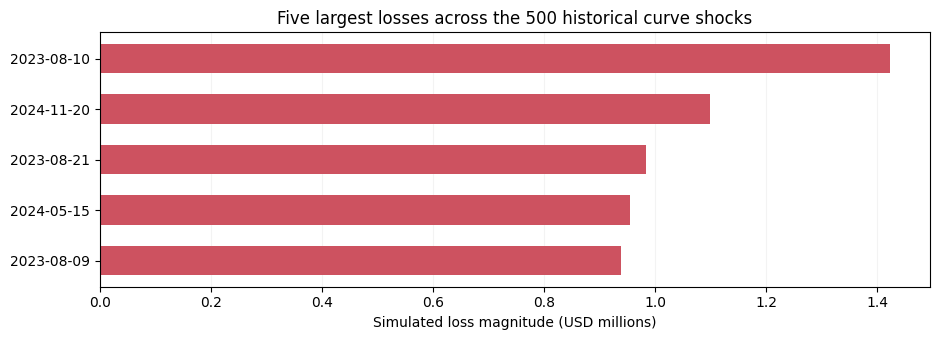

In [10]:
scenario_pnl = -moves @ L
scenario_dates = DATES[i - len(moves) + 1 : i + 1]
worst = np.argsort(scenario_pnl)[:5]
par = moves.mean(axis=1, keepdims=True) * np.ones((1, len(LAB)))
parallel_var = hs_var(L, par)
assert np.isclose(var99, -np.partition(scenario_pnl, VAR_K - 1)[VAR_K - 1])

print(f"1-day 99% Historical Simulation VaR: ${var99:,.0f}")
print(f"Parallel-only counterfactual VaR: ${parallel_var:,.0f}")
print(f"Worst modeled scenario: {scenario_dates[worst[0]].date()} "
      f"/ P&L ${scenario_pnl[worst[0]]:,.0f}")

tail = pd.DataFrame({
    "Shock date": scenario_dates[worst].strftime("%Y-%m-%d"),
    "Scenario P&L (USD)": scenario_pnl[worst],
    "Loss magnitude (USD)": -scenario_pnl[worst],
})
display(tail.style.format({"Scenario P&L (USD)": "${:,.0f}",
                           "Loss magnitude (USD)": "${:,.0f}"}))

fig, ax = plt.subplots(figsize=(9.5, 3.5))
y = np.arange(len(worst))
losses_m = -scenario_pnl[worst] / 1e6
ax.barh(y, losses_m, color="#CD5260", height=0.58)
ax.set_yticks(y, scenario_dates[worst].strftime("%Y-%m-%d"))
ax.invert_yaxis()
ax.set_xlabel("Simulated loss magnitude (USD millions)")
ax.set_title("Five largest losses across the 500 historical curve shocks")
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


## 12 · Comparing Risk Across Reporting Dates

A desk can have a similar **Net DV01** on two dates but a substantially different distribution of risk across maturities. The prior-year versus current ladder therefore provides a useful concentration view.

**Dates compared:** 2023-12-29, 2024-12-30, and 2024-12-31. The later Task 2 module explains the *drivers* of changes between consecutive reports; this module describes the two risk snapshots without assigning causality.


,Report date,Net DV01 (USD/bp),99% VaR (USD)
0,2023-12-29,"+74,369","$1,437,135"
1,2024-12-30,"+47,118","$937,426"
2,2024-12-31,"+47,234","$939,306"


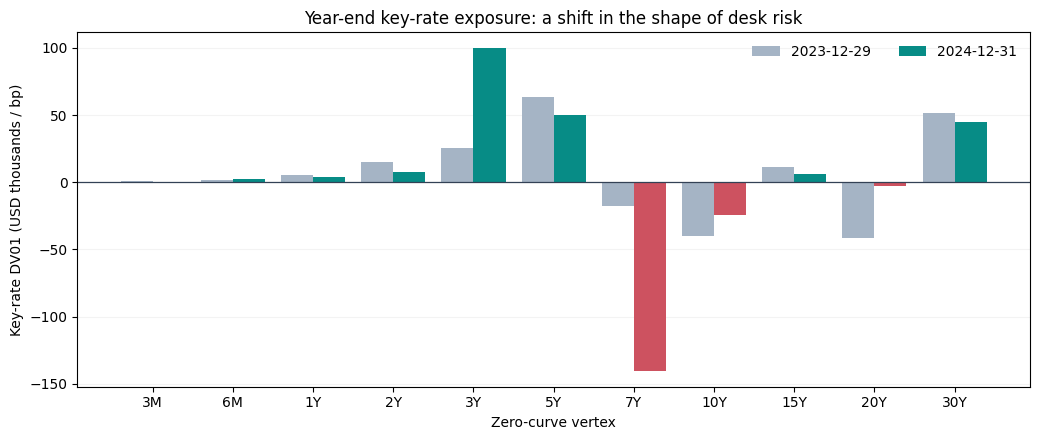

In [11]:
j = DATES.get_loc(pd.Timestamp("2023-12-29"))
_, L_year, var_year, _ = report(j)
_, L_prev, var_prev, _ = report(i - 1)

risk_comparison = pd.DataFrame({
    "Report date": [DATES[j].date(), DATES[i - 1].date(), DATES[i].date()],
    "Net DV01 (USD/bp)": [L_year.sum(), L_prev.sum(), L.sum()],
    "99% VaR (USD)": [var_year, var_prev, var99],
})
display(risk_comparison.style.format({
    "Net DV01 (USD/bp)": "{:+,.0f}",
    "99% VaR (USD)": "${:,.0f}",
}))

fig, ax = plt.subplots(figsize=(10.5, 4.5))
x = np.arange(len(LAB))
ax.bar(x - 0.2, L_year / 1000, width=0.4, color="#A5B4C5",
       label="2023-12-29")
ax.bar(x + 0.2, L / 1000, width=0.4,
       color=np.where(L >= 0, "#078C86", "#CD5260"),
       label="2024-12-31")
ax.axhline(0, color="#334155", linewidth=0.9)
ax.set_xticks(x, LAB)
ax.set_ylabel("Key-rate DV01 (USD thousands / bp)")
ax.set_xlabel("Zero-curve vertex")
ax.set_title("Year-end key-rate exposure: a shift in the shape of desk risk")
ax.legend(frameon=False, ncol=2, loc="upper right")
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


## 13 · Interpretation & Desk Takeaways

*Closing risk review | 31 December 2024 | USD, simulated portfolio*

### 13.1 · Closing risk snapshot

| Metric | Closing value | What it measures |
|:--|--:|:--|
| **Net marked portfolio value** | **USD +324.34M** | Net present value of long and short bond positions |
| **Net Key-Rate DV01** | **USD +47.23K / bp** | Approximate gain from a 1 bp parallel fall in zero rates |
| **Gross Position DV01** | **USD 600.19K / bp** | Sum of absolute bond-level DV01, before offsets |
| **1-day 99% Historical VaR** | **USD 939.31K** | Fifth-worst estimated P&L from 500 historical curve shocks |
| **Worst historical scenario** | **USD −1.42M** | Largest modeled loss among those 500 scenarios |

*Portfolio value is not gross notional or capital at risk; VaR is a model estimate rather than a guaranteed loss bound.*


### 13.2 · Three findings for the desk

**01 — Net DV01 masks offsetting exposures**

Net DV01 is approximately **+47.23K/bp**, while Gross Position DV01 is **600.19K/bp**. Opposing bond sensitivities substantially offset in the total. A single parallel-risk number does not show where the exposure sits along the curve.

**02 — Curve-shape risk matters**

The **7Y** vertex carries approximately **−140.25K/bp**, versus **+99.58K/bp** at **3Y**. These positions can respond differently to steepening, flattening, and localized changes in yields.

**03 — Tail-loss estimates depend on correlated curve moves**

Full-curve **99% Historical VaR is USD 939.31K**, compared with **USD 755.24K** for the *parallel-only counterfactual*. The counterfactual flattens every historical shock to its mean across the 11 tenors; it is a diagnostic comparison, **not a production VaR alternative**.


### 13.3 · Desk reporting decisions

| Question from Risk / Trading | Recommended report feature |
|:--|:--|
| Where is rate risk concentrated? | Show **Net DV01 and all 11 Key-Rate DV01 vertices** side by side. |
| Which trades or bonds drive the exposure? | Rank positions by **absolute DV01** with bond-level drilldown. |
| What does the loss tail look like? | Display **99% VaR**, the **five largest modeled losses**, and shock dates. |

> **Bottom line:** Portfolio value, net sensitivity, gross exposure, and tail-loss estimates answer different questions. Keep all four visible instead of relying on a single headline KPI.

*Model scope: Simulated data; first-order DV01 scenario P&L, without full repricing or explicit convexity.*


## 14 · Excel Reporting Layer (Task 1 V3)

The Python model owns **all pricing and risk calculations**. It serializes a small, auditable JSON snapshot containing the closing positions, curve ladder, historical scenarios, key report KPIs, and two PNG chart images encoded as Base64. A separate C#/.NET file reads this JSON and builds the `.xlsx` deliverable with ClosedXML.

```text
DataSource/rates_desk_feed.csv  +  Trade Blotter
                  |
                  v
       Python pricing / risk engine
                  |
                  v
     Excel_Template_Output/task1_snapshot.json
                  |
                  v
     Excel_Template_Design/DeskRiskExcel_V3.cs
                  |
                  v
     Excel_Template_Output/RatesDesk_RiskWorkstation_V3_2024-12-31.xlsx
```

**Workbook tabs:** Overview · Positions · Key Rates · Historical VaR Scenarios · Stress Lab · Methodology.

The macro-free **Stress Lab** supports pre-defined yield shocks and editable custom 11-tenor shocks. Its output is a first-order approximation $\Delta P\&L\approx -L^\top \Delta y$, **not** full bond repricing and **not** an updated Historical VaR estimate.


In [ ]:
import json
import base64
import io
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

output_dir = PROJECT_ROOT / "Excel_Template_Output"
output_dir.mkdir(parents=True, exist_ok=True)

i = len(DATES) - 1
j = DATES.searchsorted(pd.Timestamp("2023-12-29"))

pos, L, var99, moves = report(i)
_, L_prev, var_prev, _ = report(i - 1)
_, L_year, _, _ = report(j)

scenario_pnl = -moves @ L
scenario_dates = DATES[i - len(moves) + 1:i + 1]

def encode_chart(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=145,
                bbox_inches="tight", facecolor="white")
    plt.close(fig)
    return base64.b64encode(buffer.getvalue()).decode("ascii")

# Chart 1: historical vs current key-rate exposures
fig, ax = plt.subplots(figsize=(9.4, 3.15))
x = np.arange(len(LAB))

ax.bar(x - 0.19, L_year / 1000, width=0.38,
       color="#A5B4C5", label="2023-12-29")
ax.bar(x + 0.19, L / 1000, width=0.38,
       color=np.where(L >= 0, "#078C86", "#CD5260"),
       label="2024-12-31")

ax.axhline(0, color="#334155", linewidth=0.9)
ax.set_xticks(x, LAB)
ax.set_ylabel("USD thousands / bp")
ax.legend(frameon=False, loc="upper right", ncol=2)
ax.grid(axis="y", alpha=0.14)
ax.set_axisbelow(True)

curve_image = encode_chart(fig)

# Chart 2: five largest historical losses
worst = np.argsort(scenario_pnl)[:5]
losses = -scenario_pnl[worst] / 1e6
labels = [scenario_dates[k].strftime("%Y-%m-%d") for k in worst]

fig, ax = plt.subplots(figsize=(7.8, 3.1))
y = np.arange(len(worst))

ax.barh(y, losses, color="#CD5260", height=0.55)
ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.set_xlim(0, max(losses) * 1.28)
ax.set_xlabel("Loss magnitude (USD millions)")
ax.grid(axis="x", alpha=0.14)
ax.set_axisbelow(True)

for k, amount in enumerate(losses):
    ax.text(amount + max(losses) * 0.018, k,
            f"${amount:.2f}M", va="center", fontsize=9)

loss_image = encode_chart(fig)

payload = {
    "asOf": DATES[i].strftime("%Y-%m-%d"),
    "previousAsOf": DATES[i - 1].strftime("%Y-%m-%d"),
    "reportedPnl": float(PNL[i]) if np.isfinite(PNL[i]) else None,
    "previousVar": float(var_prev),
    "previousNetDv01": float(L_prev.sum()),
    "var99": float(var99),
    "curveImage": curve_image,
    "lossImage": loss_image,
    "positions": [
        {
            "bond": r.bond,
            "face_m": float(r.face_m),
            "years": float(r.years),
            "value": float(r.value),
            "dv01": float(r.dv01)
        }
        for r in pos.itertuples(index=False)
    ],
    "ladder": [
        {
            "tenor": tenor,
            "dv01": float(current),
            "yearAgo": float(previous)
        }
        for tenor, current, previous in zip(LAB, L, L_year)
    ],
    "scenarios": [
        {
            "date": date.strftime("%Y-%m-%d"),
            "pnl": float(pnl)
        }
        for date, pnl in zip(scenario_dates, scenario_pnl)
    ]
}

snapshot = output_dir / "task1_snapshot.json"
snapshot.write_text(json.dumps(payload), encoding="utf-8")

print("Snapshot ready:", snapshot)
print("Positions:", len(pos))
print("Scenarios:", len(scenario_pnl))
print("VaR:", f"${var99:,.0f}")


### 14.2 · Generate the workbook with C# (optional, Windows/.NET)

The cell below uses the **existing** `DeskRiskExcel_V3.cs` generator. It intentionally skips execution when the source file or .NET SDK is absent, so the Python-only notebook remains runnable for GitHub reviewers.

**Local usage:** On your Windows workstation, keep the generator in `Excel_Template_Design/` and ensure `dotnet --version` reports .NET 10. The snapshot export above must run first. The `.xlsx` output is normally ignored by Git because it is generated, while `.cs` and `.ipynb` source files are version-controlled.


In [ ]:
import shutil
import subprocess

CS_FILE = PROJECT_ROOT / "Excel_Template_Design" / "DeskRiskExcel_V3.cs"
JSON_FILE = PROJECT_ROOT / "Excel_Template_Output" / "task1_snapshot.json"

if not CS_FILE.is_file():
    print(f"Optional Excel export skipped: C# source not found at {CS_FILE}")
elif shutil.which("dotnet") is None:
    print("Optional Excel export skipped: .NET SDK not available in this environment")
else:
    result = subprocess.run(
        ["dotnet", "run", "--file", str(CS_FILE)],
        cwd=PROJECT_ROOT, capture_output=True, text=True,
        encoding="utf-8", errors="replace",
    )
    print("Exit Code:", result.returncode)
    print(result.stdout)
    if result.stderr.strip():
        print("STDERR:", result.stderr)
    if result.returncode != 0:
        raise RuntimeError("C# Excel workbook generation failed")


## 15 · Model Controls, Limitations & Next Module

### Controls demonstrated

| Control | Test | What it establishes |
|:--|:--|:--|
| Blotter amendment | Latest eligible ticket version replaces previous face | Positions reflect known bookings as of the date |
| Bond-to-ladder reconciliation | Bond DV01 sums to the full curve ladder | Aggregation is internally consistent |
| Bumped-price validation | Central-difference PV vs analytical DV01 | Sensitivity implementation is consistent with pricing |
| Historical window | Exactly 500 daily curve changes | Correct scenario sample length |
| JSON / C# handoff | Generator reads and reconciles snapshot | Deterministic reporting input contract |

### Deliberate limitations

- **Simulated training data**, not live market or trading-system connectivity.
- **Simplified discounting and dates:** zero curve interpolation and unadjusted coupon schedules; no full day-count, settlement, holiday, accrued interest, or curve bootstrap framework.
- **Linear risk:** DV01-based VaR and Stress Lab omit convexity and other nonlinear price effects.
- **Coverage:** no explicit credit spread, funding, liquidity, basis, or transaction-cost risk.
- **Control scope:** pricing sanity checks and accounting reconciliations do not substitute for independent market-data, model, or trade controls.
- **Reported P&L** remains external and unexplained in this module.

### Next · Task 2: Daily Risk Attribution & VaR Walk

Task 2 explains changes **between** risk reports using sequential stages: **Time/Aging → Market/Curve → Historical Window Roll → Trades/Amendments**. Task 3 then extends the system to **Predicted P&L, Reported P&L, Unexplained P&L and exceptions**.

---

**Educational project attribution:** Based on the [RiskHub Fixed Income Risk Dashboard Python Lab](https://riskhub.org/python-labs/fixed-income-risk-dashboard); enhanced with custom validation, visualizations, and a C# Excel reporting layer. *Not investment advice or a production trading system.*
